In [1]:
pip install gensim pandas scipy matplotlib seaborn scikit-learn nltk Jinja2


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from gensim.models import Word2Vec
import numpy as np
import pandas as pd
import os
import json
from scipy.spatial.distance import cosine
from sklearn.metrics.pairwise import cosine_distances
from scipy.stats import pearsonr
from sklearn.preprocessing import normalize
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy.linalg import svd
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
import copy

In [3]:
# model_12th = Word2Vec.load("Word2Vec/Exp3/model_12th.model")
model_13th = Word2Vec.load("Exp3/model_13th.model")
model_14th = Word2Vec.load("Exp3/model_14th.model")
model_15th = Word2Vec.load("Exp3/model_15th.model")
# model_16th = Word2Vec.load("Word2Vec/Exp3/model_16th.model")
model_18th = Word2Vec.load("Exp3/model_18th.model")
model_19th = Word2Vec.load("Exp3/model_19th.model")
model_20th = Word2Vec.load("Exp3/model_20th.model")

In [4]:
with open("../Data/consistent_keys_2.json", "r", encoding="utf-8") as f:
    consistent_keys = json.load(f)

In [5]:
consistent_keys

['බැවින්',
 'මා',
 'වශයෙන්',
 'එක්',
 'ක්රමයෙන්',
 'නොයෙක්',
 'යයි',
 'මාගේ',
 'යුතු',
 'පස්',
 'මේ',
 'සිට',
 'විශෙෂයෙන්',
 'දුක්',
 'යුතුය',
 'ලද්දා',
 'හා',
 'කෙරෙන්',
 'බලයෙන්',
 'සර්ව',
 'මහා',
 'වන්නේ',
 'දෙක',
 'කර',
 'තන්හි',
 'පැමිණ',
 'දී',
 'දිව්ය',
 'කරණ',
 'රූප',
 'බලා',
 'හැර',
 'යෙහි',
 'ධර්මය',
 'කරණු',
 'ඊට',
 'මෙන්',
 'වැඳ',
 'බුදුන්ගේ',
 'ලොක',
 'නැවත',
 'කල්හි',
 'එම',
 'දෙන',
 'කියන',
 'අග්ර',
 'පෙර',
 'සත්',
 'වහන්සේ',
 'යම්',
 'විය',
 'කරන්නා',
 'ධර්මයන්',
 'අතුරෙන්',
 'සිටි',
 'රන්',
 'දන්නා',
 'බවට',
 'කර්ම',
 'පටන්',
 'ගන්නා',
 'වූ',
 'සතර',
 'වසන',
 'අන්ය',
 'සර්වඥයන්',
 'ලොකයෙහි',
 'පාද',
 'සහිත',
 'කල',
 'මම',
 'සිත',
 'කොට',
 'මෙසේ',
 'පැමිණි',
 'හේ',
 'එහි',
 'එසේම',
 'හට',
 'යුතුයි',
 'ප්රකාර',
 'පිට',
 'යන',
 'පළමු',
 'තවද',
 'ආදී',
 'දෙවියන්',
 'සමග',
 'නම්',
 'කළ',
 'සකල',
 'ඇති',
 'කී',
 'පමණ',
 'ම',
 'කියා',
 'කාලයෙහි',
 'එ',
 'ගේ',
 'චන්ද්රයා',
 'එක',
 'තමන්ගේ',
 'පද',
 'යනු',
 'හෙයින්',
 'වහන්සේගේ',
 'මහ',
 'මෙහි',
 'වන',
 'සම්පූර්ණ',
 'පුර',
 'එය

In [6]:
len(consistent_keys)

210

## Orthogonal Procrustes Alignment

In [7]:
from scipy.linalg import svd
from sklearn.metrics.pairwise import cosine_similarity

In [8]:
# def align_embeddings(model_source, model_target, vocab_keys):
#     # 1. Extract Matrices (X and Y)
#     # Ensure word order is consistent across matrices
#     W_source = np.array([model_source.wv[word] for word in vocab_keys])
#     W_target = np.array([model_target.wv[word] for word in vocab_keys])

#     # 2. Orthogonal Procrustes Solution using SVD
#     # Calculate covariance matrix: A = W_source^T * W_target
#     A = W_source.T @ W_target

#     # Perform SVD: A = U * Sigma * V^T
#     U, s, Vh = svd(A)

#     # Compute the optimal orthogonal matrix Q = U * V^T
#     Q = U @ Vh

#     # 3. Apply Alignment: W_source_aligned = W_source * Q
#     W_source_aligned = W_source @ Q

#     return W_source_aligned, W_target, Q

In [9]:
#Only the one's considered for analysis
century_models = {
    13: model_13th, 
    14: model_14th, 
    15: model_15th, 
    # 16: model_16th, 
    18: model_18th, 
    19: model_19th, 
    20: model_20th
}

In [10]:
century_names = sorted(list(century_models.keys()))
# print(century_names)
n_centuries = len(century_names)

similarity_matrix = np.eye(n_centuries)
matrix_data = []

for i in range(n_centuries):
    row_data = [century_names[i]] # Start the row with the Year A label
    
    for j in range(n_centuries):
        
        source_name = century_names[i]
        target_name = century_names[j]
        
        # Handle Diagonal (Self-Similarity)
        if i == j:
            similarity_score = 1.0
            row_data.append(similarity_score)
            continue
            
        # Skip if already calculated (Symmetric Matrix - only need to calculate i < j)
        if i > j:
            similarity_score = similarity_matrix[j, i]
            row_data.append(similarity_score)
            continue
        
        model_source = century_models[source_name]
        model_target = century_models[target_name]

        # Extract Matrices
        W_source = np.array([model_source.wv[word] for word in consistent_keys])
        W_target = np.array([model_target.wv[word] for word in consistent_keys])
        
        # Orthogonal Procrustes SVD (A = W_source^T * W_target)
        A = W_source.T @ W_target
        
        # Perform SVD: A = U * Sigma * Vh
        U, s, Vh = svd(A)
        
        # Calculate the Overall Similarity Score
        overall_similarity = s.sum() / np.linalg.norm(W_target, 'fro')
        
        similarity_score = overall_similarity
        
        similarity_matrix[i, j] = similarity_score
        similarity_matrix[j, i] = similarity_score
        
        row_data.append(similarity_score)
        
    matrix_data.append(row_data)

# Prepare column names: 'Year A' followed by all century names
column_names = ['Year_A'] + century_names

# Create the final Pandas DataFrame
similarity_df = pd.DataFrame(matrix_data, 
                             columns=column_names)

# Round the values to six decimal places to match the image format
# We only round the numerical columns (columns 1 onwards)
numerical_cols = similarity_df.columns[1:]
similarity_df[numerical_cols] = similarity_df[numerical_cols].round(6)

In [11]:
similarity_df

,Year_A,13,14,15,18,19,20
0,13,1.000000,33.854248,33.619003,34.051765,33.370075,33.446301
1,14,33.854248,1.000000,20.943865,23.533369,19.947794,19.476360
2,15,33.619003,20.943865,1.000000,29.539719,26.402592,26.507530
3,18,34.051765,23.533369,29.539719,1.000000,17.405821,16.770363
4,19,33.370075,19.947794,26.402592,17.405821,1.000000,30.985600
5,20,33.446301,19.476360,26.507530,16.770363,30.985600,1.000000


In [12]:
century_names = sorted(list(century_models.keys()))
all_reference_similarity_dfs = {}

for ref_idx, ref_name in enumerate(century_names):
    
    ref_model = century_models[ref_name]
    W_ref = np.array([ref_model.wv[word] for word in consistent_keys])
    W_ref_norm = normalize(W_ref, norm='l2')
    
    aligned_vectors = {ref_name: W_ref}  # Store the reference matrix (no rotation needed)
    
    print(f"\nSetting Reference Space: {ref_name}...")
    
    #Align all OTHER centuries to this Reference Space (W_ref)
    for target_idx, target_name in enumerate(century_names):
        
        if ref_name == target_name:
            continue # Skip the self-alignment, already stored

        model_target = century_models[target_name]
        W_target = np.array([model_target.wv[word] for word in consistent_keys])
        W_target_norm = normalize(W_target, norm='l2')
                
        # We find Q to minimize || W_target * Q - W_ref ||_F^2
        A = W_target_norm.T @ W_ref_norm
        U, s, Vh = svd(A)
        Q = U @ Vh

        # Apply Alignment: W_target_aligned = W_target * Q
        W_target_aligned = W_target @ Q
        
        aligned_vectors[target_name] = W_target_aligned
        # print(f"  Aligned {target_name} to {ref_name}.")

    word_data = []
    
    for word_index, word in enumerate(consistent_keys):
        row_data = {'Key': word}
        
        # Get the reference vector (always the same for this block)
        ref_vector = W_ref[word_index].reshape(1, -1)
        
        # Calculate similarity for all aligned centuries
        for century_name in century_names:
            
            # Get the aligned vector for the current century
            current_vector = aligned_vectors[century_name][word_index].reshape(1, -1)
            
            # Calculate Cosine Similarity (1.0 = stable, 0.0 = maximum drift)
            similarity = cosine_similarity(ref_vector, current_vector)[0][0]
            row_data[century_name] = similarity
            
        word_data.append(row_data)

    similarity_df = pd.DataFrame(word_data)

    column_order = ['Key'] + century_names
    similarity_df = similarity_df[column_order]

    numerical_cols = similarity_df.columns[1:]
    similarity_df[numerical_cols] = similarity_df[numerical_cols].round(6)
    
    all_reference_similarity_dfs[ref_name] = similarity_df


Setting Reference Space: 13...

Setting Reference Space: 14...

Setting Reference Space: 15...

Setting Reference Space: 18...

Setting Reference Space: 19...

Setting Reference Space: 20...


In [13]:
from scipy.linalg import svd
from sklearn.preprocessing import normalize

# 1. Pick a global reference (earliest century)
global_ref_key = 13 
ref_model = century_models[global_ref_key]
W_ref = np.array([ref_model.wv[word] for word in consistent_keys])
W_ref_norm = normalize(W_ref, norm='l2')

# Store alignment quality metrics here
alignment_quality_metrics = []

print(f"Aligning all models to the {global_ref_key}th Century reference space...")

for target_name, model_target in century_models.items():
    if target_name == global_ref_key:
        model_target.wv.fill_norms(force=True)
        continue

    # Extract and normalize target anchors
    W_target = np.array([model_target.wv[word] for word in consistent_keys])
    W_target_norm = normalize(W_target, norm='l2')
            
    # Calculate Q (Rotation Matrix)
    A = W_target_norm.T @ W_ref_norm
    U, s, Vh = svd(A)
    Q = U @ Vh

    # --- INFUSION: MEASURE ALIGNMENT QUALITY ---
    # 1. Procrustes Disparity: Residual sum of squares after rotation
    # Formula: ||W_target_norm * Q - W_ref_norm||^2
    W_target_aligned_anchors = W_target_norm @ Q
    disparity = np.sum(np.square(W_target_aligned_anchors - W_ref_norm))
    
    # 2. Rotational Distance: How far is Q from Identity?
    # Frobenius norm of (Q - I) measures the magnitude of the rotation
    rotational_distance = np.linalg.norm(Q - np.eye(Q.shape[0]), ord='fro')

    alignment_quality_metrics.append({
        "Target_Century": target_name,
        "Reference_Century": global_ref_key,
        "Procrustes_Disparity": round(disparity, 6),
        "Rotational_Distance": round(rotational_distance, 6),
        "SVD_Singular_Sum": round(s.sum(), 6)
    })

    # --- PERMANENT IN-PLACE ROTATION ---
    model_target.wv.vectors = model_target.wv.vectors @ Q
    model_target.wv.fill_norms(force=True)
    
    print(f"  Century {target_name} aligned (Disparity: {disparity:.4f}).")

# Convert metrics to DataFrame for easy analysis
quality_df = pd.DataFrame(alignment_quality_metrics)
print("\nAlignment complete. Global coordinate system established.")

Aligning all models to the 13th Century reference space...
  Century 14 aligned (Disparity: 172.3710).
  Century 15 aligned (Disparity: 173.0435).
  Century 18 aligned (Disparity: 168.9477).
  Century 19 aligned (Disparity: 177.8479).
  Century 20 aligned (Disparity: 178.5788).

Alignment complete. Global coordinate system established.


In [14]:
quality_df

,Target_Century,Reference_Century,Procrustes_Disparity,Rotational_Distance,SVD_Singular_Sum
0,14,13,172.370956,9.931605,123.814507
1,15,13,173.043472,10.089787,123.478271
2,18,13,168.947739,9.833988,125.526131
3,19,13,177.847870,9.816673,121.076050
4,20,13,178.578842,9.979074,120.710587


In [15]:
avg_procrustes = quality_df['Procrustes_Disparity'].mean()
avg_rotational = quality_df['Rotational_Distance'].mean()

print(f"Average Procrustes Disparity: {avg_procrustes:.4f}")
print(f"Average Rotational Distance: {avg_rotational:.4f}")

Average Procrustes Disparity: 174.1578
Average Rotational Distance: 9.9302


In [16]:
quality_df.to_latex('wv_OP.md',index=False)

In [17]:
all_reference_similarity_dfs[13]

,Key,13,14,15,18,19,20
0,බැවින්,1.0,0.746771,0.614290,0.549338,0.591610,0.678186
1,මා,1.0,0.680141,0.635072,0.652202,0.442122,0.714731
2,වශයෙන්,1.0,0.452386,0.480186,0.475429,0.496352,0.586871
3,එක්,1.0,0.564041,0.649365,0.479614,0.606780,0.711927
4,ක්රමයෙන්,1.0,0.646654,0.602700,0.619842,0.551523,0.612638
...,...,...,...,...,...,...,...
205,තෙම,1.0,0.636124,0.689591,0.596321,0.515009,0.647375
206,දත්,1.0,0.629948,0.655966,0.673811,0.553563,0.596127
207,කාල,1.0,0.604072,0.662451,0.690448,0.471649,0.589876
208,කෙරෙහි,1.0,0.564612,0.512242,0.495145,0.594153,0.638759


In [18]:
list_of_dfs = []
for ref_century, similarity_df in all_reference_similarity_dfs.items():
    similarity_df['Year_A'] = ref_century
    list_of_dfs.append(similarity_df)

final_df_org = pd.concat(list_of_dfs, ignore_index=True)
final_df_org = final_df_org.sort_values(by=['Key', 'Year_A'], ascending=True).reset_index(drop=True)

In [19]:
final_df_org.head(14)

,Key,13,14,15,18,19,20,Year_A
0,අක්ෂර,1.000000,0.763506,0.641397,0.657857,0.643813,0.567147,13
1,අක්ෂර,0.763507,1.000000,0.807172,0.821184,0.699529,0.752109,14
2,අක්ෂර,0.641397,0.807172,1.000000,0.965568,0.678824,0.636382,15
3,අක්ෂර,0.657857,0.821184,0.965568,1.000000,0.671579,0.588661,18
4,අක්ෂර,0.643813,0.699529,0.678824,0.671579,1.000000,0.560932,19
5,අක්ෂර,0.567147,0.752109,0.636382,0.588661,0.560932,1.000000,20
6,අග්ර,1.000000,0.368576,0.595631,0.583631,0.577504,0.598648,13
7,අග්ර,0.368575,1.000000,0.786057,0.817265,0.601452,0.771558,14
8,අග්ර,0.595631,0.786057,1.000000,0.797203,0.511462,0.759036,15
9,අග්ර,0.583631,0.817265,0.797204,1.000000,0.767804,0.740210,18


In [20]:
output_dir = '../Data/Word_Similarity_Heatmaps_Method_2_FT'

In [21]:
font_path = '../Fonts/Noto_Sans_Sinhala/NotoSansSinhala-VariableFont_wdth,wght.ttf'
fm.fontManager.addfont(font_path)
sinhala_font_name = fm.FontProperties(fname=font_path).get_name()
fm._load_fontmanager(try_read_cache=False)

Matplotlib is building the font cache; this may take a moment.


In [22]:
for key in consistent_keys:
    key_df = final_df_org[final_df_org['Key'] == key].copy()
    year_cols = [col for col in key_df.columns if col not in ['Year_A', 'Key']]
    heatmap_data = key_df.set_index('Year_A')[year_cols].apply(pd.to_numeric, errors='coerce')
    plt.figure(figsize=(9, 7))

    sns.heatmap(
        heatmap_data, 
        annot=True,              # Show the similarity value on the cell
        fmt=".3f",               # Format the annotation to 3 decimal places
        cmap="YlGnBu",           # A nice sequential color map
        linewidths=0.5,          # Line width between cells
        linecolor='white',       # Color of the lines
        cbar_kws={'label': 'Cross-Year Word Similarity Score'} # Label for the color bar
    )

    plt.title(f'Cross-Year Cosine Similarity for Word: "{key}"', fontsize=14, fontproperties=sinhala_font_name)
    plt.xlabel('Year B (Model Version)', fontsize=12, fontproperties=sinhala_font_name)
    plt.ylabel('Year A (Model Version)', fontsize=12, fontproperties=sinhala_font_name)

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    plt.tight_layout() # Adjust plot to fit all elements
    # plt.show()
    safe_key = str(key).replace(' ', '_')
    filename = os.path.join(output_dir, f"{safe_key}.png")

    plt.savefig(
        filename, 
        dpi=300, # High resolution for better quality
        bbox_inches='tight' # Trims unnecessary white space
    )

    plt.close()
    print(f"Saved: {filename}")


Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/බැවින්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/මා.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/වශයෙන්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/එක්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/ක්රමයෙන්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/නොයෙක්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/යයි.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/මාගේ.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/යුතු.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/පස්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/මේ.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/සිට.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/විශෙෂයෙන්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/දුක්.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/යුතුය.png
Saved: ../Data/Word_Similarity_Heatmaps_Method_2_FT/ලද්දා.png
Saved: ../Data/

In [23]:
df_long = final_df_org.melt(id_vars=['Key', 'Year_A'], var_name='Year_B', value_name='Value')

In [24]:
df_long

,Key,Year_A,Year_B,Value
0,අක්ෂර,13,13,1.000000
1,අක්ෂර,14,13,0.763507
2,අක්ෂර,15,13,0.641397
3,අක්ෂර,18,13,0.657857
4,අක්ෂර,19,13,0.643813
...,...,...,...,...
7555,හෝ,14,20,0.689522
7556,හෝ,15,20,0.608959
7557,හෝ,18,20,0.592596
7558,හෝ,19,20,0.641763


In [25]:
df_long['Year_B'] = pd.to_numeric(df_long['Year_B'])

In [26]:
df_long['feature_pair'] = df_long['Year_A'].astype(str) + '_' + df_long['Year_B'].astype(str)

In [27]:
df_lags_only = df_long[df_long['Year_A'] < df_long['Year_B']]

In [28]:
piv_df_org = df_lags_only.pivot(index='Key', columns='feature_pair', values='Value')
piv_df_org['Mean_Similarity'] = piv_df_org.mean(axis=1, numeric_only=True)
piv_df_org = piv_df_org.reset_index()

In [29]:
piv_df_org.head(20)

feature_pair,Key,13_14,13_15,13_18,13_19,13_20,14_15,14_18,14_19,14_20,15_18,15_19,15_20,18_19,18_20,19_20,Mean_Similarity
0,අක්ෂර,0.763506,0.641397,0.657857,0.643813,0.567147,0.807172,0.821184,0.699529,0.752109,0.965568,0.678824,0.636382,0.671579,0.588661,0.560932,0.697044
1,අග්ර,0.368576,0.595631,0.583631,0.577504,0.598648,0.786057,0.817265,0.601452,0.771558,0.797203,0.511462,0.759036,0.767804,0.740210,0.586281,0.657488
2,අතුරෙන්,0.572444,0.499545,0.524685,0.533013,0.770721,0.726521,0.774926,0.605036,0.643524,0.634152,0.643947,0.525690,0.656463,0.530231,0.589783,0.615379
3,අන්ය,0.608526,0.616508,0.618064,0.606960,0.512104,0.670199,0.758192,0.696397,0.674937,0.489538,0.546953,0.627686,0.752611,0.639342,0.563275,0.625419
4,අනෙක,0.756970,0.573453,0.734827,0.642961,0.623799,0.666411,0.776269,0.673431,0.808384,0.633193,0.660320,0.569898,0.722822,0.775252,0.589086,0.680472
5,අප,0.570803,0.574430,0.605559,0.650861,0.580413,0.595729,0.703188,0.479894,0.520045,0.630337,0.459803,0.525977,0.624992,0.470815,0.446221,0.562604
6,අර්ථ,0.545194,0.585805,0.520519,0.617917,0.583914,0.627161,0.827885,0.649431,0.630927,0.587734,0.579204,0.707586,0.642112,0.599932,0.674526,0.625323
7,අවුත්,0.609940,0.571362,0.550823,0.536368,0.592484,0.677229,0.754305,0.527206,0.502498,0.680930,0.639911,0.677912,0.592064,0.645472,0.515562,0.604938
8,අසා,0.630254,0.476070,0.522033,0.476104,0.455931,0.754612,0.704820,0.531550,0.595383,0.612611,0.522805,0.627602,0.508123,0.565095,0.539869,0.568191
9,ආ,0.489015,0.505306,0.616224,0.599762,0.586880,0.635845,0.799511,0.620325,0.526587,0.635688,0.582520,0.698143,0.620249,0.536345,0.728075,0.612032


In [30]:
piv_df_org['Mean_Similarity'].describe()

count    210.000000
mean       0.613130
std        0.028879
min        0.520830
25%        0.592724
50%        0.613366
75%        0.630351
max        0.721899
Name: Mean_Similarity, dtype: float64

In [31]:
piv_df_org[piv_df_org['Key'] == 'සතර']

feature_pair,Key,13_14,13_15,13_18,13_19,13_20,14_15,14_18,14_19,14_20,15_18,15_19,15_20,18_19,18_20,19_20,Mean_Similarity
180,සතර,0.433528,0.5989,0.573596,0.494009,0.6505,0.495338,0.679484,0.559909,0.555904,0.783198,0.56983,0.48086,0.778334,0.782069,0.549825,0.599019


In [32]:
len(piv_df_org)

210

In [33]:
piv_df_org[piv_df_org['19_20'] > 0.6]

feature_pair,Key,13_14,13_15,13_18,13_19,13_20,14_15,14_18,14_19,14_20,15_18,15_19,15_20,18_19,18_20,19_20,Mean_Similarity
6,අර්ථ,0.545194,0.585805,0.520519,0.617917,0.583914,0.627161,0.827885,0.649431,0.630927,0.587734,0.579204,0.707586,0.642112,0.599932,0.674526,0.625323
9,ආ,0.489015,0.505306,0.616224,0.599762,0.586880,0.635845,0.799511,0.620325,0.526587,0.635688,0.582520,0.698143,0.620249,0.536345,0.728075,0.612032
10,ආදි,0.511378,0.508658,0.587639,0.687224,0.566477,0.637756,0.854365,0.567035,0.455309,0.757285,0.588918,0.614026,0.670579,0.555080,0.624507,0.612416
15,ඊට,0.576063,0.701413,0.550419,0.611615,0.591413,0.514404,0.723277,0.711977,0.581514,0.676690,0.571556,0.689749,0.524532,0.523268,0.653568,0.613431
16,උපන්,0.418438,0.510654,0.607443,0.636665,0.490820,0.605132,0.642454,0.640832,0.542282,0.665151,0.697145,0.713987,0.684239,0.669751,0.714354,0.615956
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,හා,0.617150,0.462192,0.497208,0.536235,0.440935,0.442836,0.685949,0.606870,0.679469,0.648031,0.596701,0.470747,0.653157,0.501769,0.623053,0.564153
205,හි,0.480553,0.585714,0.552822,0.536577,0.744298,0.657167,0.733801,0.701505,0.565492,0.588194,0.582911,0.524550,0.617425,0.533647,0.628165,0.602188
207,හෙවත්,0.626237,0.657866,0.515937,0.677722,0.656029,0.694169,0.787208,0.559102,0.584047,0.489339,0.561052,0.599881,0.598754,0.567384,0.677984,0.616847
208,හේ,0.647877,0.638013,0.552446,0.539718,0.605311,0.763348,0.901874,0.711128,0.691232,0.677115,0.624888,0.644917,0.556918,0.461811,0.734860,0.650097


In [34]:
piv_df_org.describe()

feature_pair,13_14,13_15,13_18,13_19,13_20,14_15,14_18,14_19,14_20,15_18,15_19,15_20,18_19,18_20,19_20,Mean_Similarity
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,0.589593,0.587992,0.597744,0.576553,0.574812,0.652012,0.744300,0.607768,0.593009,0.681016,0.598598,0.592364,0.618947,0.595858,0.586379,0.613130
std,0.081475,0.080553,0.075913,0.076673,0.085659,0.080226,0.087422,0.073379,0.077079,0.090380,0.078066,0.080556,0.078107,0.076599,0.088039,0.028879
min,0.361775,0.285511,0.428804,0.354816,0.275212,0.404328,0.439524,0.393961,0.382223,0.383963,0.277800,0.358828,0.410565,0.424269,0.357076,0.520830
25%,0.542669,0.540709,0.545342,0.531921,0.528801,0.608610,0.691583,0.567646,0.541002,0.631075,0.546529,0.536260,0.559816,0.543625,0.525920,0.592724
50%,0.595837,0.592409,0.596541,0.575040,0.582547,0.659388,0.736597,0.607607,0.594101,0.671762,0.601389,0.598990,0.616626,0.589344,0.589435,0.613366
75%,0.630425,0.642214,0.653862,0.628117,0.628031,0.703038,0.798617,0.655673,0.647917,0.724685,0.659390,0.649616,0.671329,0.646634,0.643749,0.630351
max,0.888182,0.788927,0.947372,0.774905,0.770721,0.926675,0.967226,0.788848,0.808384,0.975038,0.766378,0.759036,0.831763,0.813412,0.809375,0.721899


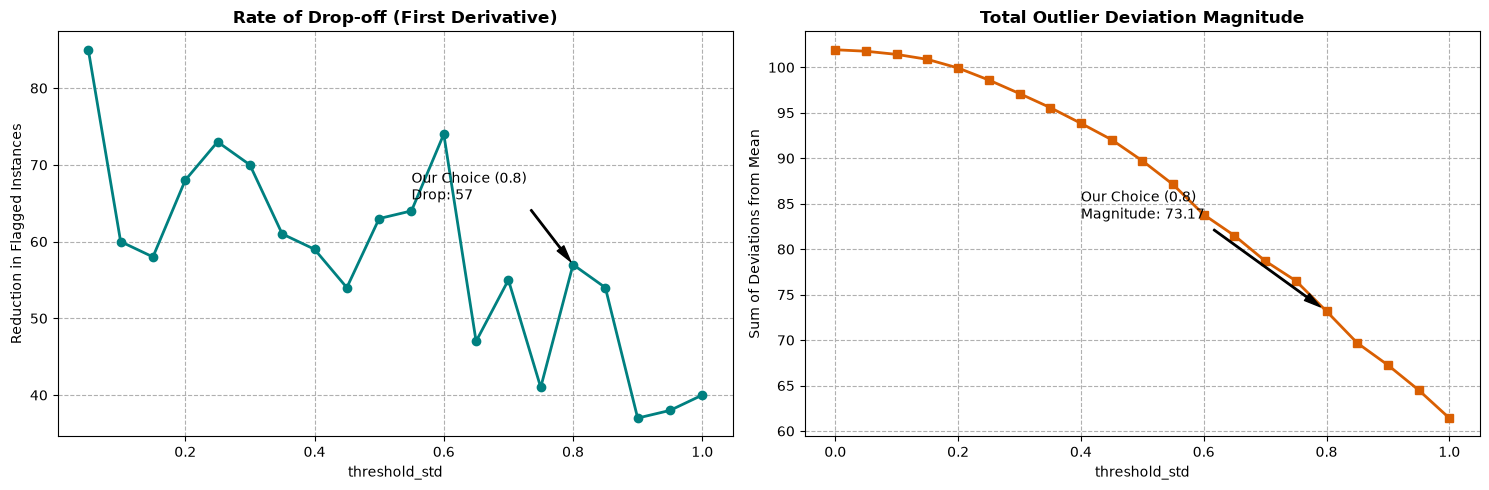

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================================
# 1. Run the Diagnostic Sweep & Collect Metrics
# =====================================================================
thresholds = np.linspace(0.0, 1.0, 21)
drift_counts = []
total_drift_magnitudes = []  # Added to track cumulative variance/intensity

work_df = piv_df_org.set_index('Key') if 'Key' in piv_df_org.columns else piv_df_org.copy()
cols = [c for c in work_df.columns if isinstance(c, str) and '_' in c]

for t in thresholds:
    total_dips = 0
    total_magnitude = 0.0
    
    for col in cols:
        series = work_df[col][work_df[col] > 0]
        if series.empty: 
            continue
            
        mean_val = series.mean()
        std_val = series.std()
        cutoff = mean_val - (t * std_val)
        
        # Filter instances below the threshold
        flagged_series = series[series < cutoff]
        total_dips += len(flagged_series)
        
        # Method 3: Track how far below the mean these anomalies actually are (variance/intensity)
        if not flagged_series.empty:
            total_magnitude += np.sum(np.abs(flagged_series - mean_val))
            
    drift_counts.append(total_dips)
    total_drift_magnitudes.append(total_magnitude)

# Convert arrays for easy vector operations
drift_counts = np.array(drift_counts)
total_drift_magnitudes = np.array(total_drift_magnitudes)

# Method 1: Calculate the Rate of Change (First Derivative) between steps
# This tells us how many fewer anomalies are caught per incremental threshold increase
rate_of_change = np.abs(np.diff(drift_counts))
thresholds_diff = thresholds[1:]

# =====================================================================
# 2. Plot the Advanced Diagnostics (Side-by-Side Subplots)
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Left Plot: Rate of Change (First Derivative) ---
ax1.plot(thresholds_diff, rate_of_change, marker='o', color='#008080', linewidth=2)
ax1.set_title('Rate of Drop-off (First Derivative)', fontsize=12, fontweight='bold')
ax1.set_xlabel('threshold_std')
ax1.set_ylabel('Reduction in Flagged Instances')
ax1.grid(True, linestyle='--')

# Highlight your 0.8 choice on the drop-off curve
if 0.8 in thresholds_diff:
    idx_08 = np.where(thresholds_diff == 0.8)[0][0]
    ax1.annotate(f'Our Choice (0.8)\nDrop: {rate_of_change[idx_08]}', 
                 xy=(0.8, rate_of_change[idx_08]), 
                 xytext=(0.55, rate_of_change[idx_08] + max(rate_of_change)*0.1),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

# --- Right Plot: Total Outlier Magnitude ---
ax2.plot(thresholds, total_drift_magnitudes, marker='s', color='#d95f02', linewidth=2)
ax2.set_title('Total Outlier Deviation Magnitude', fontsize=12, fontweight='bold')
ax2.set_xlabel('threshold_std')
ax2.set_ylabel('Sum of Deviations from Mean')
ax2.grid(True, linestyle='--')

# Highlight your 0.8 choice on the magnitude curve
idx_mag_08 = np.where(thresholds == 0.8)[0][0]
ax2.annotate(f'Our Choice (0.8)\nMagnitude: {total_drift_magnitudes[idx_mag_08]:.2f}', 
             xy=(0.8, total_drift_magnitudes[idx_mag_08]), 
             xytext=(0.4, total_drift_magnitudes[idx_mag_08] + max(total_drift_magnitudes)*0.1),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))

plt.tight_layout()
plt.show()

In [33]:
def get_semantic_drift_report(df, models_dict, threshold_std=0.8, top_n=10):
    results = []
    # Ensure 'Key' is the index
    work_df = df.set_index('Key') if 'Key' in df.columns else df.copy()
    
    # Identify all comparison columns (13_14, 13_15, 14_15, etc.)
    cols = [c for c in work_df.columns if isinstance(c, str) and '_' in c]
    
    for col in cols:
        parts = col.split('_')
        try:
            y_start, y_end = int(parts[0]), int(parts[1])
        except: continue
        
        if y_start not in models_dict or y_end not in models_dict:
            continue

        m_start = models_dict[y_start]
        m_end = models_dict[y_end]

        # Calculate a dynamic cutoff for this specific period
        series = work_df[col][work_df[col] > 0]
        if series.empty: continue
        
        cutoff = series.mean() - (threshold_std * series.std())
        dips = series[series < cutoff]
        
        for word, score in dips.items():
            try:
                # 1. Check vocab existence
                if word not in m_start.wv or word not in m_end.wv:
                    continue
                
                # 2. Dynamic top_n check to prevent IndexError
                # If vocab is smaller than requested top_n, adjust it
                v_start_size = len(m_start.wv.index_to_key)
                v_end_size = len(m_end.wv.index_to_key)
                safe_n = min(top_n, v_start_size - 1, v_end_size - 1)
                
                if safe_n < 1: continue

                # 3. Retrieve neighbors with explicit error handling for the Gensim bug
                try:
                    n_start_raw = m_start.wv.most_similar(word, topn=safe_n)
                    n_end_raw = m_end.wv.most_similar(word, topn=safe_n)
                except IndexError:
                    # If Gensim's index is still broken, force a refresh and try one last time
                    m_start.wv.fill_norms(force=True)
                    m_end.wv.fill_norms(force=True)
                    n_start_raw = m_start.wv.most_similar(word, topn=safe_n)
                    n_end_raw = m_end.wv.most_similar(word, topn=safe_n)
                
                n_start = [n[0] for n in n_start_raw]
                n_end = [n[0] for n in n_end_raw]
                
                results.append({
                    "Word": word,
                    "Period": col,
                    "Similarity": round(score, 4),
                    f"Neighbors_{y_start}": ", ".join(n_start),
                    f"Neighbors_{y_end}": ", ".join(n_end)
                })
            except Exception:
                # Catch-all for any remaining weirdness with specific words
                continue

    return pd.DataFrame(results)

In [34]:
# Execute
semantic_report = get_semantic_drift_report(piv_df_org, century_models, threshold_std=0.8)
semantic_report = semantic_report.sort_values(by=['Period', 'Similarity'])
display(semantic_report.head(30))

,Word,Period,Similarity,Neighbors_13,Neighbors_14,Neighbors_15,Neighbors_18,Neighbors_19,Neighbors_20
37,හට,13_14,0.3618,"විදර්ශකය, ශමථයානිකය, ශ්රවණාදී, අධ්යයන, ශිෂ්ය, ...","ගෙවා, පන්තිස්වන, පිළිගෙන, උයන්හි, සත්සති, බ්රහ...",NaN,NaN,NaN,NaN
0,අග්ර,13_14,0.3686,"පාර්ෂණිය, තලය, ඔබන, කලැ, පාර්ශවය, උපස්ථායක, ජි...","බොධිවජ්රාශන, මව්පිය, සාගරයෙන්, දායක, උපදනා, ගො...",NaN,NaN,NaN,NaN
21,පැමිණි,13_14,0.3752,"කොටසෙහි, පිළිගෙන, දිවජස්, දෙවිව, දෙවියන්, බහාල...","එපවත්, පනවන, මහණෙක්, වහස්නා, ගණයා, කියනුයේ, පර...",NaN,NaN,NaN,NaN
6,ඒ,13_14,0.3812,"ප්රශ්නයාගේ, ඉ, සංක්ෂෙපාර්ථයි, මුලුල්ලම, අවසානය...","රහතුන්, දේශනා, තිස්දෙනා, මහණෙනි, එම, දෙනෙකුට, ...",NaN,NaN,NaN,NaN
10,කියා,13_14,0.4032,"කිමවන, පළමුවෙනි, සරෙහි, වදෙය්ය, නුසස්, මරණෙහි,...","අර්හත්, නිශ්රය, සමෘද්ධිය, ප්රාසාදය, කළකිරී, කැ...",NaN,NaN,NaN,NaN
7,කරණ,13_14,0.4057,"නපුරු, පුරාතනාචාර්යයවරයන්, විනාශ, පොවා, නිර්දෙ...","සක්වළ, ආවාවූ, යාඥා, යී, මහසැපත්, ශාක්යරාජ, විඳ...",NaN,NaN,NaN,NaN
4,උපන්,13_14,0.4184,"නාගව, ලොව, නාග, භවනයෙන්, අවුලෙන්, උයන, වතු, ඇත...","දූතයන්, ව්යාධි, පුත්රුවනක්, මත, කිරි, ව්රසහක්ඛ...",NaN,NaN,NaN,NaN
8,කල්ප,13_14,0.4300,"සොයා, සම්බුදුරජානන්, බෝමැඩ, හිඳු, මාත්සර්යය, ම...","නොවර, තුසී, නිරතුරුව, එකාකාර, පාරමීධර්මයන්, දව...",NaN,NaN,NaN,NaN
33,සතර,13_14,0.4335,"කෙළය, ස්වෙද, ඔජොෂ්ටමකයන්ගෙ, සොළොස්, කඳුළු, චිත...","ලීලාවෙන්, මහභිනික්මන්, එකුන්, විඳ, අවුරුද්දෙහි...",NaN,NaN,NaN,NaN
34,සහිත,13_14,0.4368,"ඵලගූ, උපසපනුන්, ඉහි, ග්රහණ, ප්රකාශ, මේලෙසින්, ...","වාකචීරාදීන්, තිබූ, ක්ෂීණාශ්රවයන්, දිවිසම්, සන්...",NaN,NaN,NaN,NaN


In [35]:
semantic_report.describe()

,Similarity
count,635.000000
mean,0.497665
std,0.058123
min,0.275200
25%,0.470950
50%,0.500600
75%,0.523950
max,0.671400


In [36]:
semantic_report.to_csv('../Data/word2vec_dip_neighbors_orthogonal_procrustes.csv', index=False, encoding='utf-8-sig')

In [39]:
import pandas as pd
import numpy as np

In [40]:
semantic_report = pd.read_csv('../Data/word2vec_dip_neighbors_orthogonal_procrustes.csv', encoding='utf-8-sig')

In [41]:
semantic_report.head()

,Word,Period,Similarity,Neighbors_13,Neighbors_14,Neighbors_15,Neighbors_18,Neighbors_19,Neighbors_20
0,හට,13_14,0.3618,"විදර්ශකය, ශමථයානිකය, ශ්රවණාදී, අධ්යයන, ශිෂ්ය, ...","ගෙවා, පන්තිස්වන, පිළිගෙන, උයන්හි, සත්සති, බ්රහ...",NaN,NaN,NaN,NaN
1,අග්ර,13_14,0.3686,"පාර්ෂණිය, තලය, ඔබන, කලැ, පාර්ශවය, උපස්ථායක, ජි...","බොධිවජ්රාශන, මව්පිය, සාගරයෙන්, දායක, උපදනා, ගො...",NaN,NaN,NaN,NaN
2,පැමිණි,13_14,0.3752,"කොටසෙහි, පිළිගෙන, දිවජස්, දෙවිව, දෙවියන්, බහාල...","එපවත්, පනවන, මහණෙක්, වහස්නා, ගණයා, කියනුයේ, පර...",NaN,NaN,NaN,NaN
3,ඒ,13_14,0.3812,"ප්රශ්නයාගේ, ඉ, සංක්ෂෙපාර්ථයි, මුලුල්ලම, අවසානය...","රහතුන්, දේශනා, තිස්දෙනා, මහණෙනි, එම, දෙනෙකුට, ...",NaN,NaN,NaN,NaN
4,කියා,13_14,0.4032,"කිමවන, පළමුවෙනි, සරෙහි, වදෙය්ය, නුසස්, මරණෙහි,...","අර්හත්, නිශ්රය, සමෘද්ධිය, ප්රාසාදය, කළකිරී, කැ...",NaN,NaN,NaN,NaN


In [42]:
sorted_report = semantic_report.sort_values(by='Similarity', ascending=True)

In [43]:
sorted_report.head(6)

,Word,Period,Similarity,Neighbors_13,Neighbors_14,Neighbors_15,Neighbors_18,Neighbors_19,Neighbors_20
166,යට,13_20,0.2752,"ව්යාධීන්, ව්යාධි, ආතුර, අෂ්ටාංගායුර්වෙදයෙහි, ය...",NaN,NaN,NaN,NaN,"තදාසන්න, ගමරාළගේ, ප්රදේශවල, සිතීය, වාක්යයෙහි, ..."
399,කරන්නා,15_19,0.2778,NaN,NaN,"ඉස්න, සිංචනය, ලෙස, රයාගේදළැස, කොපුල්අත, ලලාටාක...",NaN,"වාසී, මැදුරක්, මෘගයා, අනංග, ත්රිපිටකධාරී, ගන්ධ...",NaN
39,සියලු,13_15,0.2855,"අවිභාගයෙන්, ආර්යය, මාර්ගාඛ්ය, පුරවන්නා, කුසලෙහ...",NaN,"නිමල්, කාල, අක්ෂි, කෙරේ෴, එහි, ඇමකල්, යුවලැස, ...",NaN,NaN,NaN
167,කෙනෙක්,13_20,0.2889,"තෙජො, ජීවිතඤ්චාති, පරිපාචනය, ඔජට්ඨමකඤ්චව, පීතා...",NaN,NaN,NaN,NaN,"ප්රණක්ෂර, ලිප, ප්රීතියෙන්, නොහික්මුණු, කඩදාසිය..."
168,ගත්,13_20,0.3194,"ගාත්රාක්ෂරය, අර්ධ, කතුවරයෝ, කිරීමට, හේතු, යුහු...",NaN,NaN,NaN,NaN,"දිටිමිමම, කෙනෙකු, සතුරන්ගෙ, කොපුවෙන්, අසිපත්, ..."
169,එම,13_20,0.3299,"ආර්යය, භූමියෙහි, ගතයන්, අධිගතයන්, රූපයහ, දශක, ...",NaN,NaN,NaN,NaN,"දුටොත්, කොටවු, තක්, බැබල, ශාක්ය, රජුට, පැමිණිය..."


In [44]:
semantic_report['Similarity'] = semantic_report['Similarity'].round(4)
split_periods = semantic_report['Period'].str.split('_', expand=True)
ref_num = split_periods[0]
target_num = split_periods[1]

semantic_report['Reference Century'] = ref_num + 'th'
semantic_report['Target Century'] = target_num + 'th'

In [45]:
def get_top_5_from_col(row, century_num):
    col_name = f'Neighbors_{century_num}'
    
    # Check if the column exists and has data for this row
    if col_name in row.index and pd.notna(row[col_name]) and row[col_name] != '':
        # Split by comma, clean up spaces, and grab the first 5 words
        words = [w.strip() for w in str(row[col_name]).split(',') if w.strip()]
        return ', '.join(words[:5])
    
    return '' # Return empty if no data found

# 4. Extract neighbors dynamically for both Reference and Target
semantic_report['Ref Century Neighbors'] = semantic_report.apply(
    lambda r: get_top_5_from_col(r, r['Period'].split('_')[0]), axis=1
)

semantic_report['Target Century Neighbors'] = semantic_report.apply(
    lambda r: get_top_5_from_col(r, r['Period'].split('_')[1]), axis=1
)


In [46]:
final_df = semantic_report[[
    'Word', 
    'Similarity',
    'Reference Century', 
    'Ref Century Neighbors', 
    'Target Century', 
    'Target Century Neighbors'
]].copy()

In [47]:
final_df.head()

,Word,Similarity,Reference Century,Ref Century Neighbors,Target Century,Target Century Neighbors
0,හට,0.3618,13th,"විදර්ශකය, ශමථයානිකය, ශ්රවණාදී, අධ්යයන, ශිෂ්ය",14th,"ගෙවා, පන්තිස්වන, පිළිගෙන, උයන්හි, සත්සති"
1,අග්ර,0.3686,13th,"පාර්ෂණිය, තලය, ඔබන, කලැ, පාර්ශවය",14th,"බොධිවජ්රාශන, මව්පිය, සාගරයෙන්, දායක, උපදනා"
2,පැමිණි,0.3752,13th,"කොටසෙහි, පිළිගෙන, දිවජස්, දෙවිව, දෙවියන්",14th,"එපවත්, පනවන, මහණෙක්, වහස්නා, ගණයා"
3,ඒ,0.3812,13th,"ප්රශ්නයාගේ, ඉ, සංක්ෂෙපාර්ථයි, මුලුල්ලම, අවසානයෙහි",14th,"රහතුන්, දේශනා, තිස්දෙනා, මහණෙනි, එම"
4,කියා,0.4032,13th,"කිමවන, පළමුවෙනි, සරෙහි, වදෙය්ය, නුසස්",14th,"අර්හත්, නිශ්රය, සමෘද්ධිය, ප්රාසාදය, කළකිරී"


In [48]:
final_df = final_df.sort_values(by='Similarity', ascending=True)

In [49]:
final_df.head()

,Word,Similarity,Reference Century,Ref Century Neighbors,Target Century,Target Century Neighbors
166,යට,0.2752,13th,"ව්යාධීන්, ව්යාධි, ආතුර, අෂ්ටාංගායුර්වෙදයෙහි, යෙත්",20th,"තදාසන්න, ගමරාළගේ, ප්රදේශවල, සිතීය, වාක්යයෙහි"
399,කරන්නා,0.2778,15th,"ඉස්න, සිංචනය, ලෙස, රයාගේදළැස, කොපුල්අත",19th,"වාසී, මැදුරක්, මෘගයා, අනංග, ත්රිපිටකධාරී"
39,සියලු,0.2855,13th,"අවිභාගයෙන්, ආර්යය, මාර්ගාඛ්ය, පුරවන්නා, කුසලෙහි",15th,"නිමල්, කාල, අක්ෂි, කෙරේ෴, එහි"
167,කෙනෙක්,0.2889,13th,"තෙජො, ජීවිතඤ්චාති, පරිපාචනය, ඔජට්ඨමකඤ්චව, පීතා...",20th,"ප්රණක්ෂර, ලිප, ප්රීතියෙන්, නොහික්මුණු, කඩදාසිය"
168,ගත්,0.3194,13th,"ගාත්රාක්ෂරය, අර්ධ, කතුවරයෝ, කිරීමට, හේතු",20th,"දිටිමිමම, කෙනෙකු, සතුරන්ගෙ, කොපුවෙන්, අසිපත්"


In [50]:
final_df['Ref Century Neighbors'] = '\\iffalse ' + final_df['Ref Century Neighbors'].astype(str) + ' \\fi'
final_df['Target Century Neighbors'] = '\\iffalse ' + final_df['Target Century Neighbors'].astype(str) + ' \\fi'

In [51]:
float_formatter = lambda x: f"{x:.4f}".rstrip('0').rstrip('.') if isinstance(x, float) else str(x)

In [52]:
final_df.head(6).to_latex('../Data/Word2Vec_Semantic_Drift_Report_OPA.tex', index=False, encoding='utf-8-sig', escape=False, formatters={'Similarity': float_formatter})